# Classification - Mini-Project 2

***Edit this cell with your name(s), tutorial number(s) and ID(s)***

---

Name:

ID:

Tutorial:

---

Name:

ID:

Tutorial:

---


## Dataset Description

The following dataset includes information about loan applicants, including factors such as income, credit score, employment status, loan details, and other indicators of financial stability, along with the final decision showing whether each loan was approved or not.

| Column | Description|
|-|-|
|ApplicationNumber|Unique identifier assigned to each loan application|
|Age|Applicant’s age in years|
|AnnualIncome|Applicant’s yearly income|
|CreditScore|A score representing the applicant’s creditworthiness|
|EmploymentStatus|Applicant’s current employment situation (Employed, Unemployed, Self-Employed)|
|EducationLevel|Highest educational qualification attained (Highschool, Bachelor, Master, Doctorate, Diploma)|
|LoanAmount|Total amount of money requested for the loan|
|LoanDuration|Duration of the loan in months|
|MaritalStatus|Applicant’s marital state (Divorced, Married, Single, Widowed)|
|NumberOfDependents|Number of individuals financially dependent on the applicant|
|HomeOwnershipStatus|Applicant’s housing status (Mortagage, Own, Rent, Other)|
|BankruptcyHistory|Indicates whether the applicant has previously declared bankruptcy (0 = No, 1 = Yes)|
|LoanPurpose|The primary reason for taking the loan (Debt Consolidation, Home Improvement, Education, Personal)|
|PreviousLoanDefaults|Indicates if the applicant has defaulted on any previous loans (0 = No, 1 = Yes)|
|MonthlyLoanPayment|Amount the applicant would need to pay monthly to repay the loan|
|MonthlyIncome|Average monthly income of the applicant|
|JobTenure|Number of years the applicant has been in their current job|
|LoanApproved|Indicates loan approval status (0 = Not Approved, 1 = Approved)|

## Importing Libraries & Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, precision_score, recall_score, accuracy_score, roc_auc_score)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

df = pd.read_csv('https://raw.githubusercontent.com/GUC-DM/W2026/main/data/loan_data.csv')
df.head()

,ApplicationNumber,Age,AnnualIncome,CreditScore,EmploymentStatus,EducationLevel,LoanAmount,LoanDuration,MaritalStatus,NumberOfDependents,HomeOwnershipStatus,BankruptcyHistory,LoanPurpose,PreviousLoanDefaults,MonthlyLoanPayment,MonthlyIncome,JobTenure,LoanApproved
0,26231,18,"$26,992.00",586,Employed,Diploma,"$22,432.00",36 months,Single,3,Mortgage,0,Debt Consolidation,0,$623.11,"$2,249.33",3,No
1,13176,18,"$22,825.00",581,Self-Employed,Master,"$30,457.00",24 months,Single,0,Rent,0,Home Improvement,0,"$1,269.04","$1,902.08",5,No
2,27751,18,"$75,891.00",522,Employed,Bachelor,"$30,583.00",96 months,Married,2,Mortgage,0,Personal,0,$318.57,"$6,324.25",6,No
3,20628,18,"$92,094.00",565,Employed,Bachelor,"$72,738.00",36 months,Single,1,Mortgage,0,Vehicle,0,NaN,"$7,674.50",3,No
4,28773,18,"$35,686.00",554,Employed,Diploma,"$28,021.00",36 months,Married,3,Rent,0,Home Improvement,0,$778.36,"$2,973.83",1,No


## Data Inspection

Before changing anything, we wanted to get a feel for the data: how big it is, what type each column is, and where values are missing.

In [2]:
# Number of rows and columns
print("Shape:", df.shape)

# Data types and non-null counts per column
df.info()

Shape: (20000, 18)
<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   ApplicationNumber     20000 non-null  int64
 1   Age                   20000 non-null  int64
 2   AnnualIncome          20000 non-null  str  
 3   CreditScore           20000 non-null  int64
 4   EmploymentStatus      16260 non-null  str  
 5   EducationLevel        20000 non-null  str  
 6   LoanAmount            20000 non-null  str  
 7   LoanDuration          20000 non-null  str  
 8   MaritalStatus         20000 non-null  str  
 9   NumberOfDependents    20000 non-null  int64
 10  HomeOwnershipStatus   20000 non-null  str  
 11  BankruptcyHistory     20000 non-null  int64
 12  LoanPurpose           20000 non-null  str  
 13  PreviousLoanDefaults  20000 non-null  int64
 14  MonthlyLoanPayment    15660 non-null  str  
 15  MonthlyIncome         17160 non-null  str  
 

A few things stood out straight away. There are 20,000 applications and 18 columns. The money columns (AnnualIncome, LoanAmount, MonthlyLoanPayment and MonthlyIncome) are stored as text, because of the dollar signs and commas, so we can't do any maths on them yet. LoanDuration is text too ("36 months"). Three columns have missing values: EmploymentStatus, MonthlyLoanPayment and MonthlyIncome.

In [3]:
# Count and percentage of missing values per column (only columns that have any)
nulls = df.isna().sum()
pd.DataFrame({"missing": nulls, "percent": (nulls / len(df) * 100).round(2)})[nulls > 0]

,missing,percent
EmploymentStatus,3740,18.7
MonthlyLoanPayment,4340,21.7
MonthlyIncome,2840,14.2


In [4]:
# Look at a few raw values of the text columns that should be numeric
df[["AnnualIncome", "LoanAmount", "LoanDuration", "MonthlyLoanPayment", "MonthlyIncome"]].sample(5, random_state=1)

,AnnualIncome,LoanAmount,LoanDuration,MonthlyLoanPayment,MonthlyIncome
11456,"$51,648.00","$13,329.00",24 months,$555.38,"$4,304.00"
16528,"$46,451.00","$38,507.00",60 months,NaN,"$3,870.92"
3253,"$39,357.00","$38,440.00",48 months,$800.83,"$3,279.75"
18614,"$29,793.00","$22,170.00",72 months,NaN,"$2,482.75"
1544,"$93,182.00","$34,330.00",60 months,$572.17,"$7,765.17"


In [5]:
# Unique values of every categorical column to spot spelling / case inconsistencies
cat_cols = ["EmploymentStatus", "EducationLevel", "LoanDuration", "MaritalStatus",
            "HomeOwnershipStatus", "LoanPurpose", "LoanApproved"]
for col in cat_cols:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False).to_string(), "\n")

--- EmploymentStatus ---
EmploymentStatus
Employed         13866
NaN               3740
Self-Employed     1273
Unemployed        1121 

--- EducationLevel ---
EducationLevel
Bachelor       6054
High School    5908
Diploma        4034
Master         3050
Doctorate       954 

--- LoanDuration ---
LoanDuration
48 months     3991
60 months     3982
36 months     3971
72 months     2046
24 months     1972
84 months     1059
96 months     1001
12 months      959
120 months     537
108 months     482 

--- MaritalStatus ---
MaritalStatus
Married     10041
Single       6078
Divorced     2882
Widowed       999 

--- HomeOwnershipStatus ---
HomeOwnershipStatus
Mortgage    7939
Rent        6087
Own         3938
Other       2036 

--- LoanPurpose ---
LoanPurpose
Home Improvement      5925
Debt Consolidation    5027
Vehicle               4034
Education             3008
Personal              2006 

--- LoanApproved ---
LoanApproved
No     15185
Yes     4745
no        35
yes       35 



The target column is messy: it has "Yes", "yes", "No" and "no", which are really just two answers written differently. The description says it should be 0 and 1, so we'll fix that. The other categorical columns looked fine to us.

We also noticed that most loans are rejected (around 76%), so the classes are unbalanced. We kept that in mind for later, because it changes which metric makes sense.

In [6]:
# Summary statistics of the columns that are already numeric
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ApplicationNumber,20000.0,20500.50000,5773.647028,10501.0,15500.75,20500.5,25500.25,30500.0
Age,20000.0,39.75260,11.622713,18.0,32.00,40.0,48.00,80.0
CreditScore,20000.0,571.61240,50.997358,343.0,540.00,578.0,609.00,712.0
NumberOfDependents,20000.0,1.51730,1.386325,0.0,0.00,1.0,2.00,5.0
BankruptcyHistory,20000.0,0.00000,0.000000,0.0,0.00,0.0,0.00,0.0
PreviousLoanDefaults,20000.0,0.10005,0.300074,0.0,0.00,0.0,0.00,1.0
JobTenure,20000.0,5.00265,2.236804,0.0,3.00,5.0,6.00,16.0


In [7]:
# Check for duplicated rows and duplicated application numbers
print("Duplicated rows:", df.duplicated().sum())
print("Duplicated ApplicationNumber:", df["ApplicationNumber"].duplicated().sum())

Duplicated rows: 0
Duplicated ApplicationNumber: 0


There are no duplicate rows, which is good. Age, credit score, dependents and job tenure all have sensible ranges. The odd one out is BankruptcyHistory, which is 0 for every single person. It can't tell approved and rejected applicants apart, so we'll drop it before modelling.

## Data Cleaning

### 1. Turning the money columns into numbers
We strip out the $ signs and commas and convert the columns to numbers. The missing values stay empty for now; we deal with them later.

In [8]:
money_cols = ["AnnualIncome", "LoanAmount", "MonthlyLoanPayment", "MonthlyIncome"]

print("Before:")
print(df[money_cols].dtypes, "\n")

# Remove '$' and ',' then convert to numeric (vectorised over each whole column)
df[money_cols] = df[money_cols].apply(lambda col: pd.to_numeric(col.str.replace(r"[$,]", "", regex=True)))

print("After:")
print(df[money_cols].dtypes)
df[money_cols].head()

Before:
AnnualIncome          str
LoanAmount            str
MonthlyLoanPayment    str
MonthlyIncome         str
dtype: object 

After:
AnnualIncome          float64
LoanAmount            float64
MonthlyLoanPayment    float64
MonthlyIncome         float64
dtype: object


,AnnualIncome,LoanAmount,MonthlyLoanPayment,MonthlyIncome
0,26992.0,22432.0,623.11,2249.33
1,22825.0,30457.0,1269.04,1902.08
2,75891.0,30583.0,318.57,6324.25
3,92094.0,72738.0,NaN,7674.50
4,35686.0,28021.0,778.36,2973.83


### 2. Turning LoanDuration into a number
We only need the number of months, so "36 months" just becomes 36.

In [9]:
print("Before:", df["LoanDuration"].unique()[:5], df["LoanDuration"].dtype)

# Extract the digits from strings like "36 months"
df["LoanDuration"] = df["LoanDuration"].str.extract(r"(\d+)")[0].astype(int)

print("After: ", np.sort(df["LoanDuration"].unique()), df["LoanDuration"].dtype)

Before: <StringArray>
['36 months', '24 months', '96 months', '72 months', '48 months']
Length: 5, dtype: str str
After:  [ 12  24  36  48  60  72  84  96 108 120] int64


### 3. Fixing the target labels
We lowercase everything first so "Yes" and "yes" become the same, then map yes to 1 and no to 0.

In [10]:
print("Before:")
print(df["LoanApproved"].value_counts(), "\n")

df["LoanApproved"] = df["LoanApproved"].str.strip().str.lower().map({"yes": 1, "no": 0})

print("After:")
print(df["LoanApproved"].value_counts())

Before:
LoanApproved
No     15185
Yes     4745
no        35
yes       35
Name: count, dtype: int64 

After:
LoanApproved
0    15220
1     4780
Name: count, dtype: int64


### 4. Checking that the two income columns agree
Monthly income should just be annual income divided by 12, so we checked whether that's actually true in the data.

In [11]:
# Difference between the stored monthly income and annual income / 12 (only where both exist)
income_gap = (df["MonthlyIncome"] - df["AnnualIncome"] / 12).abs()
consistent = income_gap <= 0.01          # allow for rounding to cents

print("Rows where MonthlyIncome == AnnualIncome / 12:", consistent.sum())
print("Rows where MonthlyIncome is missing:", df["MonthlyIncome"].isna().sum())
mismatch = df["MonthlyIncome"].notna() & ~consistent
print("Rows that disagree:", mismatch.sum())

# How large is the disagreement?
ratio = (df.loc[mismatch, "AnnualIncome"] / 12) / df.loc[mismatch, "MonthlyIncome"]
ratio.describe()

Rows where MonthlyIncome == AnnualIncome / 12: 16997
Rows where MonthlyIncome is missing: 2840
Rows that disagree: 163


count    163.000000
mean       1.767074
std        0.148853
min        1.500089
25%        1.635779
50%        1.775061
75%        1.893382
max        1.999971
dtype: float64

It is true for almost every row, but there are 163 rows where the two numbers don't match (the annual figure is 1.5 to 2 times too big). We had no way of knowing which of the two values was the wrong one. Income turned out to be the most important column for the decision, so we didn't want to guess and simply removed those rows. That's less than 1% of the data, so we don't lose much.

In [12]:
print("Rows before:", len(df))
df = df[~mismatch].copy()
print("Rows after: ", len(df))

# Re-check: every remaining row with a monthly income now matches annual / 12
check = (df["MonthlyIncome"] - df["AnnualIncome"] / 12).abs()
print("Remaining mismatches:", (check > 0.01).sum())

Rows before: 20000
Rows after:  19837
Remaining mismatches: 0


### 5. Filling missing values
We handled each column on its own, because the right fix depends on the column.

MonthlyIncome (about 14% missing): we'd just shown that monthly income is annual income divided by 12, and annual income is never missing. So instead of filling the gaps with an average, we can work out the exact value.

In [13]:
print("Missing before:", df["MonthlyIncome"].isna().sum())
df["MonthlyIncome"] = df["MonthlyIncome"].fillna((df["AnnualIncome"] / 12).round(2))
print("Missing after: ", df["MonthlyIncome"].isna().sum())

Missing before: 2840
Missing after:  0


MonthlyLoanPayment (about 22% missing): we wondered if this could also be calculated. When we divided the payment by the loan amount, we got exactly 1 divided by the number of months every time (see the table). So the payment is simply the loan amount spread evenly over the months, and we can fill in the exact value here as well.

In [14]:
# Ratio of payment to loan amount, grouped by loan duration, compared with 1 / duration
check = (df["MonthlyLoanPayment"] / df["LoanAmount"]).groupby(df["LoanDuration"]).agg(["mean", "std"])
check["1 / duration"] = 1 / check.index
check

,mean,std,1 / duration
LoanDuration,,,
12,0.083333,1.653455e-07,0.083333
24,0.041667,1.674802e-07,0.041667
36,0.027778,1.702057e-07,0.027778
48,0.020833,1.639663e-07,0.020833
60,0.016667,1.626161e-07,0.016667
72,0.013889,1.694310e-07,0.013889
84,0.011905,1.665814e-07,0.011905
96,0.010417,1.777917e-07,0.010417
108,0.009259,1.623857e-07,0.009259


In [15]:
print("Missing before:", df["MonthlyLoanPayment"].isna().sum())
df["MonthlyLoanPayment"] = df["MonthlyLoanPayment"].fillna((df["LoanAmount"] / df["LoanDuration"]).round(2))
print("Missing after: ", df["MonthlyLoanPayment"].isna().sum())

Missing before: 4311
Missing after:  0


EmploymentStatus (about 19% missing): this one we can't calculate. The usual trick is to fill it with the most common value, "Employed", but that would mean calling around 3,700 people employed with nothing to back it up. Before deciding, we checked how the missing rows compare with the others.

In [16]:
# Approval rate and count per employment status, treating missing as its own group
df.groupby(df["EmploymentStatus"].fillna("Missing"))["LoanApproved"].agg(approval_rate="mean", count="size").round(3)

,approval_rate,count
EmploymentStatus,,
Employed,0.239,13754
Missing,0.242,3710
Self-Employed,0.278,1263
Unemployed,0.184,1110


The missing group doesn't really look like any of the other groups, so we gave it its own label, "Unknown". We keep all the rows this way and don't pretend to know something we don't.

In [17]:
print("Before:"); print(df["EmploymentStatus"].value_counts(dropna=False), "\n")
df["EmploymentStatus"] = df["EmploymentStatus"].fillna("Unknown")
print("After:");  print(df["EmploymentStatus"].value_counts(dropna=False))

Before:
EmploymentStatus
Employed         13754
NaN               3710
Self-Employed     1263
Unemployed        1110
Name: count, dtype: int64 

After:
EmploymentStatus
Employed         13754
Unknown           3710
Self-Employed     1263
Unemployed        1110
Name: count, dtype: int64


In [18]:
# Final check: no missing values remain anywhere
df.isna().sum()

ApplicationNumber       0
Age                     0
AnnualIncome            0
CreditScore             0
EmploymentStatus        0
EducationLevel          0
LoanAmount              0
LoanDuration            0
MaritalStatus           0
NumberOfDependents      0
HomeOwnershipStatus     0
BankruptcyHistory       0
LoanPurpose             0
PreviousLoanDefaults    0
MonthlyLoanPayment      0
MonthlyIncome           0
JobTenure               0
LoanApproved            0
dtype: int64

### 6. New column: Monthly_Debt_To_Income_Ratio
There's no separate debt column in the data, so we used the monthly loan payment as the person's monthly debt:

Monthly_Debt_To_Income_Ratio = MonthlyLoanPayment / MonthlyIncome

For example, a value of 0.30 means 30% of someone's monthly income would go towards the loan. The lower it is, the easier the loan should be to afford.

In [19]:
df["Monthly_Debt_To_Income_Ratio"] = df["MonthlyLoanPayment"] / df["MonthlyIncome"]

# Show the new column next to the columns used to build it
display(df[["MonthlyLoanPayment", "MonthlyIncome", "Monthly_Debt_To_Income_Ratio"]].head())
df["Monthly_Debt_To_Income_Ratio"].describe()

,MonthlyLoanPayment,MonthlyIncome,Monthly_Debt_To_Income_Ratio
0,623.11,2249.33,0.277020
1,1269.04,1902.08,0.667185
2,318.57,6324.25,0.050373
3,2020.50,7674.50,0.263274
4,778.36,2973.83,0.261737


count    19837.000000
mean         0.175797
std          0.208654
min          0.003365
25%          0.058492
50%          0.111857
75%          0.211474
max          3.729336
Name: Monthly_Debt_To_Income_Ratio, dtype: float64

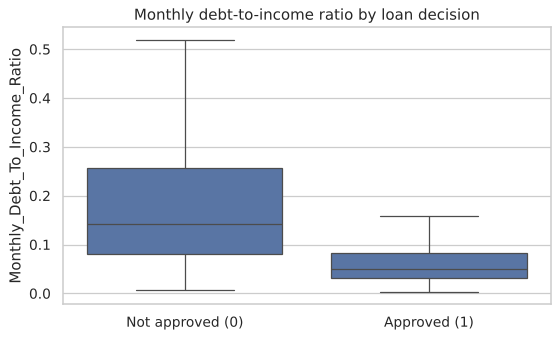

In [20]:
# Does the ratio differ between approved and rejected applicants?
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=df, x="LoanApproved", y="Monthly_Debt_To_Income_Ratio", showfliers=False, ax=ax)
ax.set_xticks([0, 1], ["Not approved (0)", "Approved (1)"])
ax.set_xlabel("")
ax.set_title("Monthly debt-to-income ratio by loan decision")
plt.show()

As we expected, approved applicants have a much lower ratio than rejected ones, so the new column looks useful.

### 7. Checking for outliers
We drew boxplots of the main numeric columns to see if anything looked extreme.

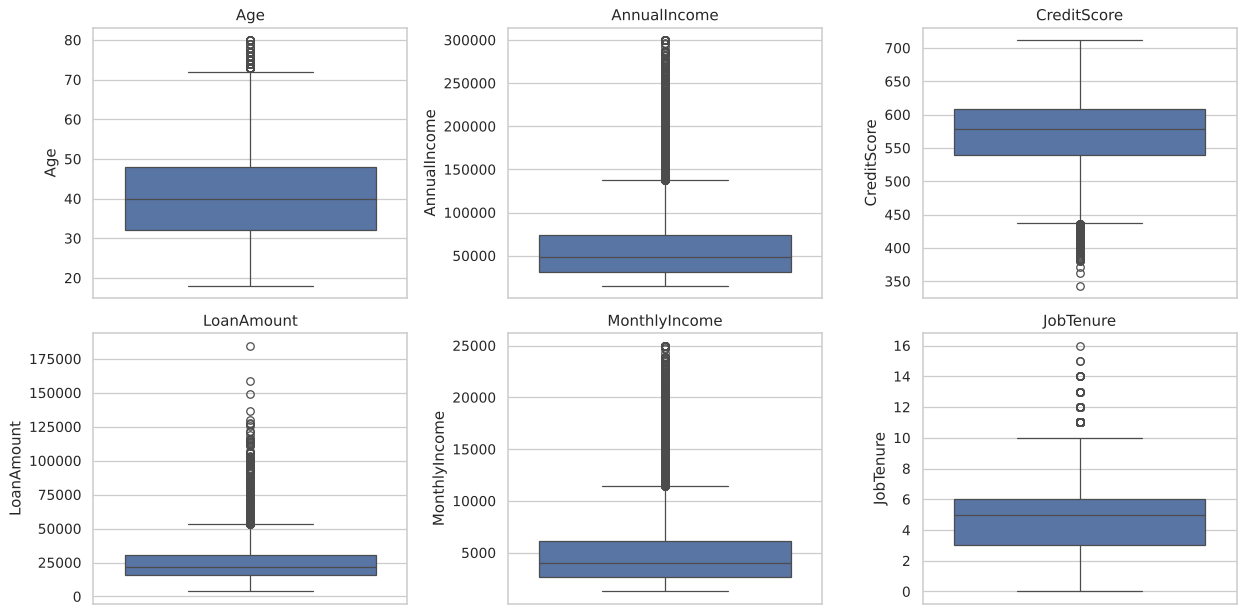

In [21]:
num_cols = ["Age", "AnnualIncome", "CreditScore", "LoanAmount", "MonthlyIncome", "JobTenure"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

A small number of people have very high incomes or very large loans. These look like real people rather than typos, so we kept them. They don't really bother a decision tree anyway, since it only checks whether a value is above or below a cut-off.

One thing we noticed: 584 people have an annual income of exactly $15,000. It looks like a minimum value built into the data, so we left it as it is.

In [22]:
print("Final cleaned shape:", df.shape)
df.info()

Final cleaned shape: (19837, 19)
<class 'pandas.DataFrame'>
Index: 19837 entries, 0 to 19999
Data columns (total 19 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   ApplicationNumber             19837 non-null  int64  
 1   Age                           19837 non-null  int64  
 2   AnnualIncome                  19837 non-null  float64
 3   CreditScore                   19837 non-null  int64  
 4   EmploymentStatus              19837 non-null  str    
 5   EducationLevel                19837 non-null  str    
 6   LoanAmount                    19837 non-null  float64
 7   LoanDuration                  19837 non-null  int64  
 8   MaritalStatus                 19837 non-null  str    
 9   NumberOfDependents            19837 non-null  int64  
 10  HomeOwnershipStatus           19837 non-null  str    
 11  BankruptcyHistory             19837 non-null  int64  
 12  LoanPurpose                   19837 non-nul

## Exploratory Data Analysis

**Q1: On average, which type of educational level gets more approval?**

**Visualization**

Since LoanApproved is 0 or 1, taking its average for each education level gives the approval rate of that group. We went with a bar chart sorted from highest to lowest because it makes the ranking easy to see.

EducationLevel
Doctorate      44.03 %
Master         35.12 %
Bachelor       26.63 %
Diploma        20.44 %
High School    14.41 %
Name: LoanApproved, dtype: str


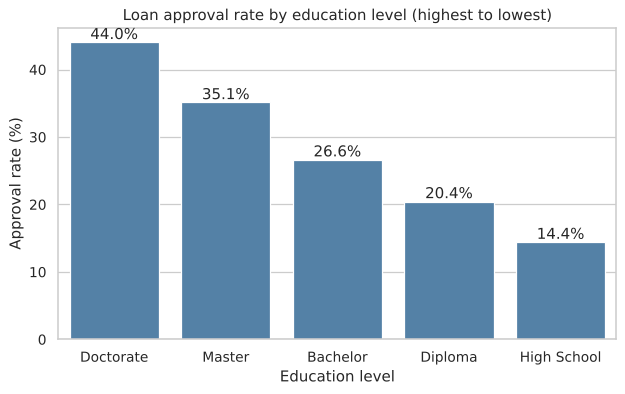

In [23]:
# Approval rate per education level, sorted descending
edu_rate = df.groupby("EducationLevel")["LoanApproved"].mean().sort_values(ascending=False)
print((edu_rate * 100).round(2).astype(str) + " %")

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=edu_rate.index, y=edu_rate.values * 100, order=edu_rate.index, color="steelblue", ax=ax)
for i, v in enumerate(edu_rate.values * 100):
    ax.text(i, v + 0.5, f"{v:.1f}%", ha="center")
ax.set_xlabel("Education level")
ax.set_ylabel("Approval rate (%)")
ax.set_title("Loan approval rate by education level (highest to lowest)")
plt.show()

**Answer for Q1**: Doctorate holders have the highest approval rate, at about 44%. After them come Master (35%), Bachelor (27%), Diploma (20%) and High School (14%). It goes down step by step as the education level drops, and a Doctorate holder is roughly three times as likely to be approved as someone with only High School. We think a big part of this is income: more educated people tend to earn more, and income turned out to be what matters most to the model.

**Q2: How does the annual income vary among approved applicants?**

**Visualization**

The question asks about quartiles, and a boxplot shows those directly, so that's what we used, looking only at approved applicants. We put a histogram next to it so you can also see the overall shape.

Q1 (25%): $67,248
Q2 (median): $90,939
Q3 (75%): $122,930
IQR: $55,682
Median income of rejected applicants: $40,422


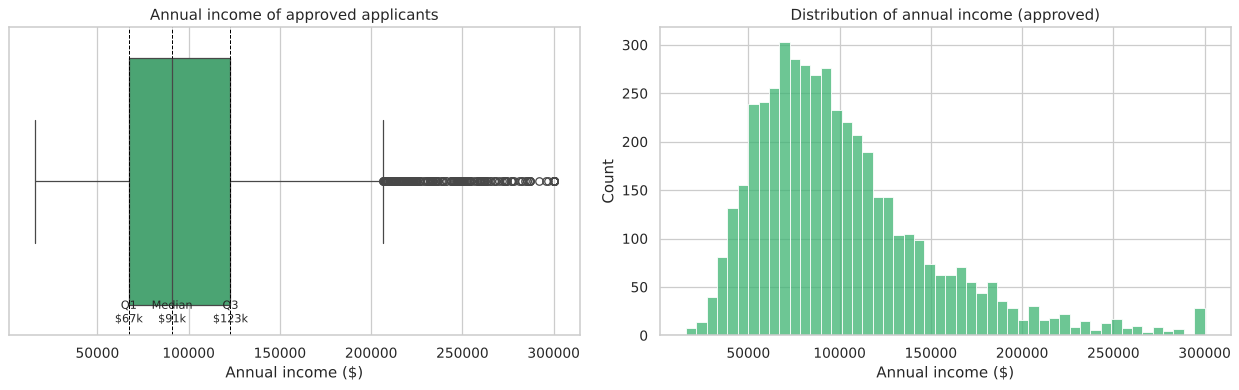

In [24]:
approved_income = df.loc[df["LoanApproved"] == 1, "AnnualIncome"]
q1, q2, q3 = approved_income.quantile([0.25, 0.5, 0.75])
print(f"Q1 (25%): ${q1:,.0f}")
print(f"Q2 (median): ${q2:,.0f}")
print(f"Q3 (75%): ${q3:,.0f}")
print(f"IQR: ${q3 - q1:,.0f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(x=approved_income, ax=axes[0], color="mediumseagreen")
for q, name in zip([q1, q2, q3], ["Q1", "Median", "Q3"]):
    axes[0].axvline(q, ls="--", color="black", lw=0.8)
    axes[0].text(q, 0.47, f"{name}\n${q/1000:.0f}k", ha="center", va="bottom", fontsize=9)
axes[0].set_title("Annual income of approved applicants")
axes[0].set_xlabel("Annual income ($)")

sns.histplot(approved_income, bins=50, ax=axes[1], color="mediumseagreen")
axes[1].set_title("Distribution of annual income (approved)")
axes[1].set_xlabel("Annual income ($)")
plt.tight_layout()
plt.show()

# For comparison: median income of rejected applicants
print(f"Median income of rejected applicants: ${df.loc[df['LoanApproved'] == 0, 'AnnualIncome'].median():,.0f}")

**Answer for Q2**: The three quartiles for approved applicants are:

Q1 = \$67,248. A quarter of approved people earn less than this, so not many approved people are on a low income.

Q2 (median) = \$90,939. Half earn less than this and half earn more. For comparison, the median for rejected people is only about \$40,400, less than half of this, which shows how much income matters.

Q3 = \$122,930. Three quarters earn less than this, and the top quarter earns more.

So incomes among approved people still vary a lot. The middle half alone covers a range of about \$55,700, and a handful of people earn all the way up to \$300,000. Those are the dots on the right of the boxplot.

**Q3: How does the age of an applicant affect their credit score?**

**Visualization**

Age and credit score are both numbers, so a scatter plot made the most sense. The red line of best fit shows the overall trend, and we also printed the correlation to see how strong it is.

Line of best fit: CreditScore = 1.42 * Age + 515.2
Pearson correlation: 0.323


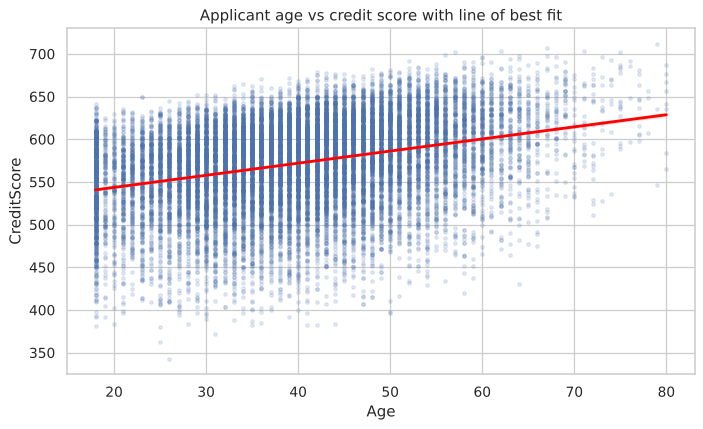

In [25]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.regplot(data=df, x="Age", y="CreditScore", ax=ax,
            scatter_kws={"alpha": 0.15, "s": 8}, line_kws={"color": "red"})
ax.set_title("Applicant age vs credit score with line of best fit")
plt.show()

slope, intercept = np.polyfit(df["Age"], df["CreditScore"], 1)
corr = df["Age"].corr(df["CreditScore"])
print(f"Line of best fit: CreditScore = {slope:.2f} * Age + {intercept:.1f}")
print(f"Pearson correlation: {corr:.3f}")

**Answer for Q3**: Older applicants tend to have slightly higher credit scores. The line goes up by about 1.4 points for each extra year of age, and the correlation is about 0.32, so it's a moderate positive relationship. That makes sense to us, because the older you are, the longer you've had to build up a credit history. The points are very spread out around the line, though, so age on its own doesn't tell you much about any one person's score. There are plenty of young people with high scores and older people with low ones.

**Q4: What is the distribution of applicants' income per month?**

**Visualization**

A histogram is the easiest way to see the shape of a distribution. We also drew lines for the mean and the median: if the data were normal they'd be almost on top of each other, and if it's skewed the mean gets pulled towards the long tail. Finally, we printed the skewness (0 would mean perfectly symmetric).

Skewness: 1.99


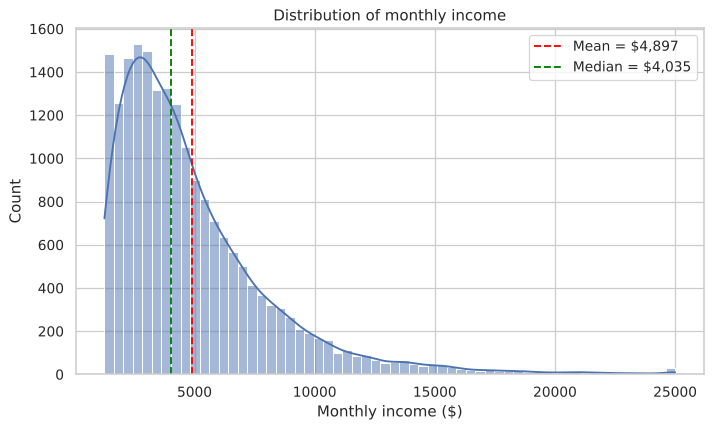

In [26]:
income_m = df["MonthlyIncome"]
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(income_m, bins=60, kde=True, ax=ax)
ax.axvline(income_m.mean(), color="red", ls="--", label=f"Mean = ${income_m.mean():,.0f}")
ax.axvline(income_m.median(), color="green", ls="--", label=f"Median = ${income_m.median():,.0f}")
ax.set_title("Distribution of monthly income")
ax.set_xlabel("Monthly income ($)")
ax.legend()
plt.show()

print(f"Skewness: {income_m.skew():.2f}")

**Answer for Q4**: It's not normal. It's clearly skewed to the right. Most people earn somewhere between \$2,000 and \$6,000 a month, but there's a long tail of people earning a lot more, up to \$25,000. The skewness is about 2.0, which is far from 0. The mean (\$4,897) is also noticeably higher than the median (\$4,035), because those few very high incomes drag the mean up. Because of this, the median is the better number to quote if you want to describe a typical applicant's income.

## Data Preparation for Modelling

### Choosing the columns
We dropped three columns:
- ApplicationNumber, because it's just an ID and says nothing about the person.
- BankruptcyHistory, because it's always 0, so it can't help.
- AnnualIncome, because after cleaning it's exactly MonthlyIncome times 12, so keeping both would be repeating ourselves.

Everything else stays, including our new ratio column. LoanApproved is what we're predicting.

### Encoding the text columns
The model only works with numbers, so the text columns need converting.

EducationLevel has a natural order (High School, Diploma, Bachelor, Master, Doctorate), so we just numbered it 0 to 4. That's ordinal encoding, and it lets the tree ask things like "Bachelor or higher?".

EmploymentStatus, MaritalStatus, HomeOwnershipStatus and LoanPurpose don't have any order. Numbering them 0, 1, 2 would make the model think one category is "bigger" than another, which doesn't make sense. So we used one-hot encoding instead, which gives each category its own 0/1 column. We dropped the first category of each, since you can tell it's that one when all the others are 0.

We didn't scale anything, because a decision tree doesn't care about the scale of the numbers.

In [27]:
model_df = df.drop(columns=["ApplicationNumber", "BankruptcyHistory", "AnnualIncome"])

# Ordinal encoding for education
edu_order = {"High School": 0, "Diploma": 1, "Bachelor": 2, "Master": 3, "Doctorate": 4}
model_df["EducationLevel"] = model_df["EducationLevel"].map(edu_order)

# One-hot encoding for nominal categories
nominal = ["EmploymentStatus", "MaritalStatus", "HomeOwnershipStatus", "LoanPurpose"]
model_df = pd.get_dummies(model_df, columns=nominal, drop_first=True, dtype=int)

print("Shape after encoding:", model_df.shape)
model_df.head()

Shape after encoding: (19837, 25)


,Age,CreditScore,EducationLevel,LoanAmount,LoanDuration,NumberOfDependents,PreviousLoanDefaults,MonthlyLoanPayment,MonthlyIncome,JobTenure,LoanApproved,Monthly_Debt_To_Income_Ratio,EmploymentStatus_Self-Employed,EmploymentStatus_Unemployed,EmploymentStatus_Unknown,MaritalStatus_Married,MaritalStatus_Single,MaritalStatus_Widowed,HomeOwnershipStatus_Other,HomeOwnershipStatus_Own,HomeOwnershipStatus_Rent,LoanPurpose_Education,LoanPurpose_Home Improvement,LoanPurpose_Personal,LoanPurpose_Vehicle
0,18,586,1,22432.0,36,3,0,623.11,2249.33,3,0,0.277020,0,0,0,0,1,0,0,0,0,0,0,0,0
1,18,581,3,30457.0,24,0,0,1269.04,1902.08,5,0,0.667185,1,0,0,0,1,0,0,0,1,0,1,0,0
2,18,522,2,30583.0,96,2,0,318.57,6324.25,6,0,0.050373,0,0,0,1,0,0,0,0,0,0,0,1,0
3,18,565,2,72738.0,36,1,0,2020.50,7674.50,3,0,0.263274,0,0,0,0,1,0,0,0,0,0,0,0,1
4,18,554,1,28021.0,36,3,0,778.36,2973.83,1,0,0.261737,0,0,0,1,0,0,0,0,1,0,1,0,0


### Splitting into training and test data
We set aside 20% of the data for testing, and the model never sees it while learning. That way the test score tells us how it would do on new applicants. We used stratify so both parts keep the same share of approved loans (about 24%).

In [28]:
X = model_df.drop(columns="LoanApproved")
y = model_df["LoanApproved"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Approval rate train: {:.3f}  test: {:.3f}".format(y_train.mean(), y_test.mean()))

Train: (15869, 24)  Test: (3968, 24)
Approval rate train: 0.239  test: 0.239


## Modelling

### Which metric do we use?
Only about 24% of loans are approved. That means a "model" that just rejects everyone would already be 76% accurate, while being completely useless. So we didn't want to rely on accuracy.

Instead, we focused on the approved class:
- Precision: out of the loans the model approves, how many are actually good? If this is low, the bank is handing out risky loans.
- Recall: out of all the good loans, how many does the model catch? If this is low, the bank is turning good customers away.
- F1-score: a single number that balances the two, and is only high when both are. We used F1 as our main metric.

### Choosing the tree size
If you let a tree grow as deep as it wants, it ends up memorising the training data and doing worse on new data (overfitting). So we tried a range of depths and compared their F1 scores with 5-fold cross-validation, which tests each setting on five different slices of the training data.

In [29]:
# Compare tree depths with 5-fold cross-validation (scored by F1 on the approved class)
param_grid = {"max_depth": [2, 3, 4, 5, 6, 8, 10, 15, None], "min_samples_leaf": [1, 20, 50]}
grid = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid, scoring="f1", cv=5)
grid.fit(X_train, y_train)

cv = pd.DataFrame(grid.cv_results_)
cv["max_depth"] = cv["param_max_depth"].astype(str)
best_per_depth = cv.groupby("max_depth", sort=False)["mean_test_score"].max().round(3)
print("Best CV F1 for each max_depth:")
print(best_per_depth.to_string())
print("\nOverall best:", grid.best_params_, "CV F1 =", round(grid.best_score_, 3))

Best CV F1 for each max_depth:
max_depth
2     0.659
3     0.687
4     0.712
5     0.720
6     0.707
8     0.722
10    0.717
15    0.717

Overall best: {'max_depth': 8, 'min_samples_leaf': 50} CV F1 = 0.722


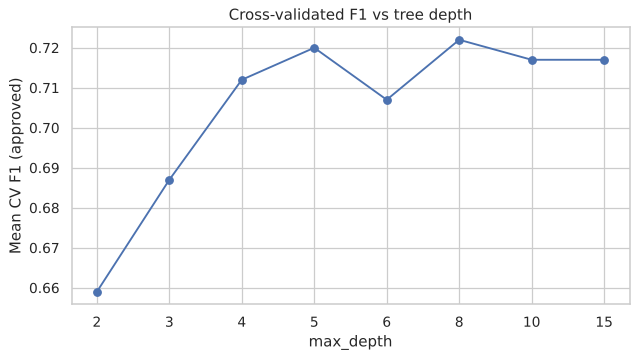

In [30]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(best_per_depth.index, best_per_depth.values, marker="o")
ax.set_xlabel("max_depth")
ax.set_ylabel("Mean CV F1 (approved)")
ax.set_title("Cross-validated F1 vs tree depth")
plt.show()

F1 gets better up to a depth of around 4 or 5, and after that it basically stops improving. The very best setting was depth 8 (F1 of 0.722), but that's only about 0.01 better than depth 4 (0.712), and a depth-8 tree is far too big for anyone to actually read. Loan decisions should be explainable, and Q5 asks us to read the rules from the tree, so we went with max_depth = 4. We also set min_samples_leaf = 20 so that no final box is based on just a handful of people.

In [31]:
# Final decision tree
tree = DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=42)
tree.fit(X_train, y_train)

print("Train F1: {:.3f}".format(f1_score(y_train, tree.predict(X_train))))
print("Test  F1: {:.3f}".format(f1_score(y_test, tree.predict(X_test))))

Train F1: 0.714
Test  F1: 0.710


**Q5: Display the Decision Tree after modelling and comment briefly on how the rules are split. Write in English one of the rules of an approved loan in the tree.**

**Visualization**

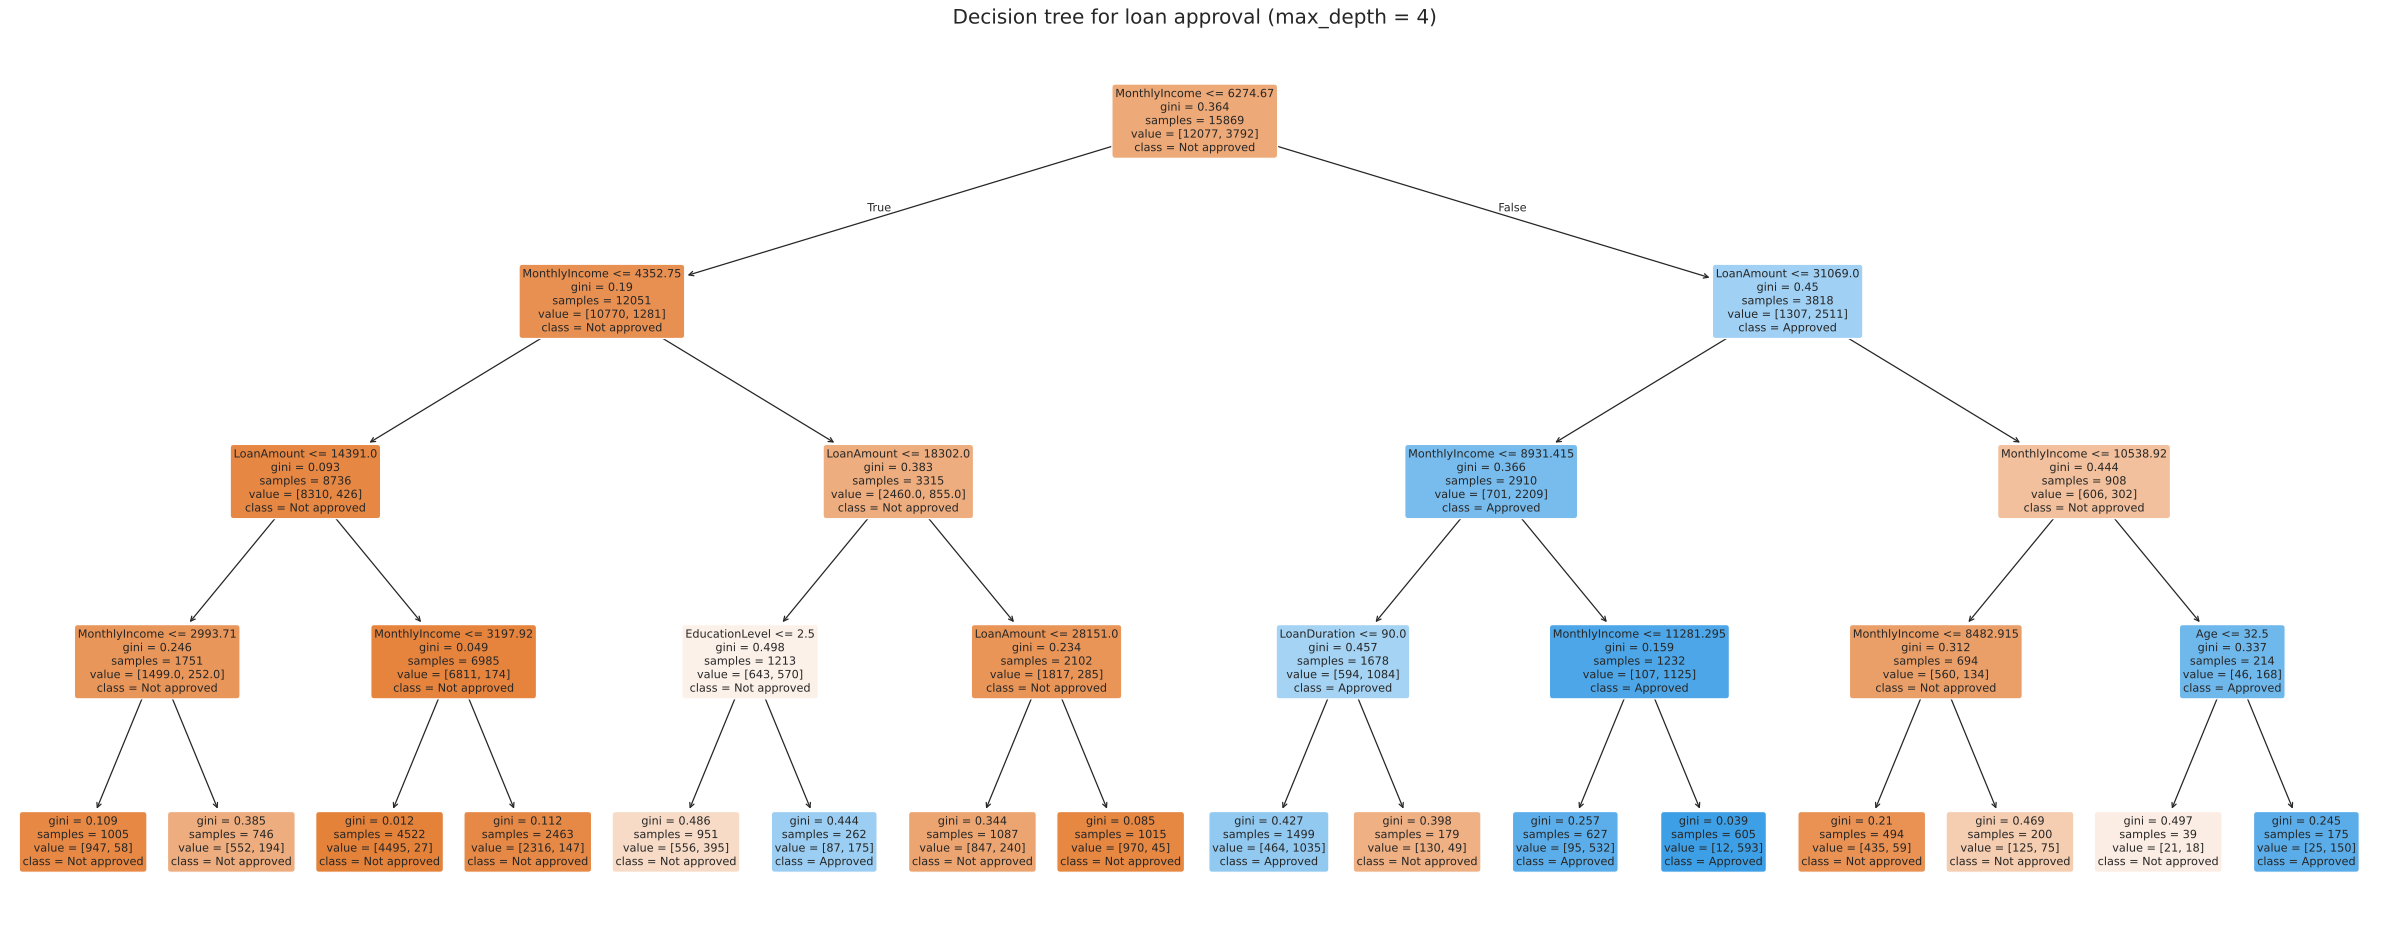

In [32]:
fig, ax = plt.subplots(figsize=(34, 13))
plot_tree(tree, feature_names=X.columns, class_names=["Not approved", "Approved"],
          filled=True, rounded=True, fontsize=9, proportion=False, impurity=True, ax=ax)
ax.set_title("Decision tree for loan approval (max_depth = 4)", fontsize=16)
plt.show()

In [33]:
# Text version of the same tree, which makes the exact thresholds easy to read
print(export_text(tree, feature_names=list(X.columns), decimals=2))

|--- MonthlyIncome <= 6274.67
|   |--- MonthlyIncome <= 4352.75
|   |   |--- LoanAmount <= 14391.00
|   |   |   |--- MonthlyIncome <= 2993.71
|   |   |   |   |--- class: 0
|   |   |   |--- MonthlyIncome >  2993.71
|   |   |   |   |--- class: 0
|   |   |--- LoanAmount >  14391.00
|   |   |   |--- MonthlyIncome <= 3197.92
|   |   |   |   |--- class: 0
|   |   |   |--- MonthlyIncome >  3197.92
|   |   |   |   |--- class: 0
|   |--- MonthlyIncome >  4352.75
|   |   |--- LoanAmount <= 18302.00
|   |   |   |--- EducationLevel <= 2.50
|   |   |   |   |--- class: 0
|   |   |   |--- EducationLevel >  2.50
|   |   |   |   |--- class: 1
|   |   |--- LoanAmount >  18302.00
|   |   |   |--- LoanAmount <= 28151.00
|   |   |   |   |--- class: 0
|   |   |   |--- LoanAmount >  28151.00
|   |   |   |   |--- class: 0
|--- MonthlyIncome >  6274.67
|   |--- LoanAmount <= 31069.00
|   |   |--- MonthlyIncome <= 8931.42
|   |   |   |--- LoanDuration <= 90.00
|   |   |   |   |--- class: 1
|   |   |   |--- Loan

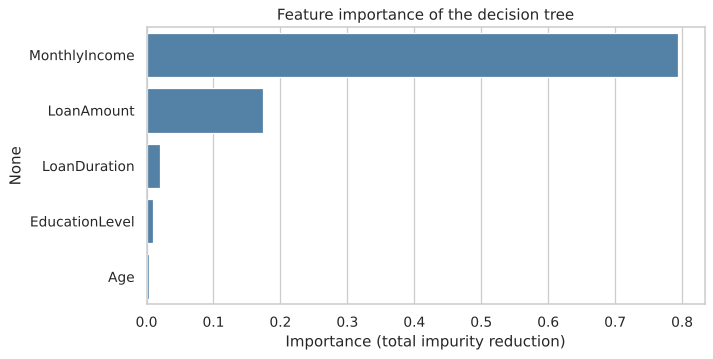

MonthlyIncome     0.794
LoanAmount        0.174
LoanDuration      0.019
EducationLevel    0.009
Age               0.004
dtype: float64

In [34]:
# Which features does the tree rely on most?
importance = pd.Series(tree.feature_importances_, index=X.columns).sort_values(ascending=False)
importance = importance[importance > 0]
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=importance.values, y=importance.index, color="steelblue", ax=ax)
ax.set_title("Feature importance of the decision tree")
ax.set_xlabel("Importance (total impurity reduction)")
plt.show()
importance.round(3)

**Answer for Q5**: The tree starts by asking about monthly income (is it above \$6,274.67?), and income keeps coming back further down too. It's by far the most important column. Loan amount comes second. Loan duration, education and age only show up in a few small splits near the bottom.

Put simply, the tree has learned that people with a high income asking for a reasonable amount get approved, while people with a low income or asking for a very large loan get rejected. Nearly every leaf on the low-income (left) side says "Not approved".

We were a bit surprised that our ratio column, credit score and previous defaults don't appear at all. We think it's because income and loan amount already carry most of that information. The ratio is literally built from those two.

Here's one rule for an approved loan, picked because it only takes three questions to reach:

If someone's monthly income is more than \$6,274.67, the loan they ask for is \$31,069 or less, and their monthly income is also more than \$11,281.29, then the loan is approved.

There are 605 people from the training data in this leaf, and 593 of them (98%) really were approved, so it's a very dependable rule. In everyday terms, if you earn more than about \$11,300 a month and ask for no more than about \$31,000, you're almost certainly getting the loan.

## Evaluation

In [35]:
y_pred = tree.predict(X_test)
y_prob = tree.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, target_names=["Not approved", "Approved"], digits=3))
print("ROC-AUC: {:.3f}".format(roc_auc_score(y_test, y_prob)))

# Baseline for comparison: always predict "not approved"
print("Accuracy of a model that rejects everyone: {:.3f}".format((y_test == 0).mean()))

              precision    recall  f1-score   support

Not approved      0.896     0.944     0.919      3020
    Approved      0.784     0.650     0.710       948

    accuracy                          0.873      3968
   macro avg      0.840     0.797     0.815      3968
weighted avg      0.869     0.873     0.869      3968

ROC-AUC: 0.914
Accuracy of a model that rejects everyone: 0.761


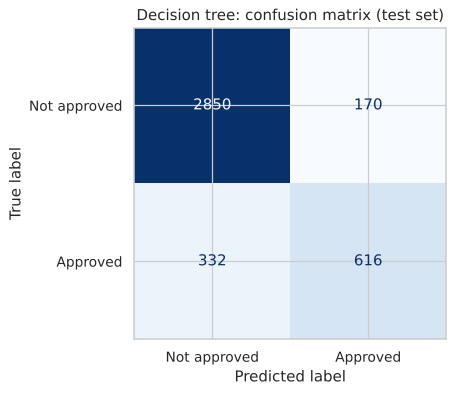

In [36]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["Not approved", "Approved"]).plot(
    ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("Decision tree: confusion matrix (test set)")
plt.show()

How did the decision tree do?

| Metric (test data) | Value |
|-|-|
| F1 (approved) | 0.710 |
| Precision (approved) | 0.784 |
| Recall (approved) | 0.650 |
| Accuracy | 0.873 |
| ROC-AUC | 0.914 |

The F1 score on the test data is 0.71, and on the training data it's almost the same (0.714). That tells us the model isn't overfitting: it does just as well on applicants it has never seen.

Precision is 0.78, so when the tree says "approve", it's right about 78% of the time. Out of 786 approvals, 170 went to people who should have been rejected.

Recall is 0.65, so the tree finds 616 of the 948 good loans and misses the other 332. In other words, the model is on the cautious side: it's more likely to turn down a good applicant than to approve a bad one. For a bank, that's probably the better mistake to make, since a loan that isn't paid back costs more than a customer who goes elsewhere.

Accuracy is 87%, compared with 76% for the "reject everyone" approach, so the tree is genuinely adding something.

Our recommendation: the tree works well as a simple, explainable tool, because the bank can show exactly why a loan was approved or rejected. Since it does miss some good applicants, we'd suggest letting it approve the clear-cut cases automatically and having a person look over the borderline rejections.

## Bonus (Optional)

Bonus: Random Forest vs Decision Tree

A Random Forest builds lots of decision trees, each trained on a random slice of the data, and lets them vote. One tree's mistakes tend to get outvoted by the others, so a forest usually predicts better than a single tree. We used the same training and test data and the same metric (F1), so the comparison is fair.

In [37]:
# ---------------- BONUS: Random Forest ----------------
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
rf_prob = rf.predict_proba(X_test)[:, 1]
print(classification_report(y_test, rf_pred, target_names=["Not approved", "Approved"], digits=3))

              precision    recall  f1-score   support

Not approved      0.913     0.950     0.931      3020
    Approved      0.817     0.713     0.762       948

    accuracy                          0.893      3968
   macro avg      0.865     0.832     0.847      3968
weighted avg      0.890     0.893     0.891      3968



,Decision Tree,Random Forest
F1 (approved),0.710,0.762
Precision (approved),0.784,0.817
Recall (approved),0.650,0.713
Accuracy,0.873,0.893
ROC-AUC,0.914,0.943


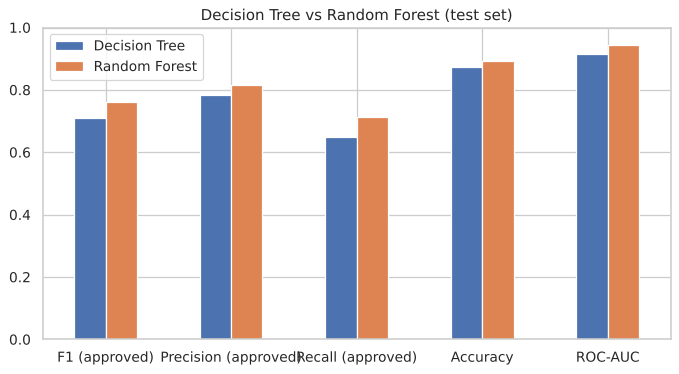

In [38]:
# Side-by-side comparison on the test set
def scores(pred, prob):
    return {"F1 (approved)": f1_score(y_test, pred), "Precision (approved)": precision_score(y_test, pred),
            "Recall (approved)": recall_score(y_test, pred), "Accuracy": accuracy_score(y_test, pred),
            "ROC-AUC": roc_auc_score(y_test, prob)}

comparison = pd.DataFrame({"Decision Tree": scores(y_pred, y_prob), "Random Forest": scores(rf_pred, rf_prob)}).round(3)
display(comparison)

ax = comparison.plot(kind="bar", figsize=(9, 4.5), rot=0)
ax.set_ylim(0, 1)
ax.set_title("Decision Tree vs Random Forest (test set)")
plt.show()

Bonus: which one would we pick?

The Random Forest wins on every metric. F1 goes up from 0.710 to 0.762, and precision (0.78 to 0.82) and recall (0.65 to 0.71) both improve. That means it approves fewer risky people and misses fewer good ones at the same time.

If we just care about getting the predictions right, we'd choose the Random Forest, since it gives a clearly better F1, which is our main metric. The catch is that you can't really draw 300 trees or turn them into simple rules like we did in Q5. So in practice, we'd let the Random Forest make the decisions and keep the single decision tree around to explain the main rules to customers.